# Frente 3 — Carreira: trajetória e objetivos

**PRO3201 — Estatística e Aplicações · Grupo 10 (J)**

**Pergunta da frente:** como a vivência no grupo de extensão se conecta ao horizonte profissional de curto prazo (estágio e objetivo atual) e de médio prazo (área pretendida após a formatura)?

### Como ler este notebook

- **Leia como um artigo.** As células de código só chamam funções com nomes autoexplicativos (em inglês, pela convenção do README). A lógica fica em `src/`:
  - `stats_tests.py`: testes da disciplina;
  - `regression.py`: regressão linear múltipla;
  - `carreira.py`: preparação dos dados e agrupamentos;
  - `plotting/plots_carreira.py`: gráficos.
- **Cada pergunta segue os itens (a) a (e) do guia:** hipóteses; teste e premissas; resultado; gráfico ou tabela; conclusão para o relatório.
- **Métodos:** só os da disciplina (qui-quadrado, ANOVA com Bartlett e Scheffé, regressão linear com F parcial), α = 5%.
- **Perguntas do guia cortadas:**
  - P5 (o estágio derruba as horas no grupo): praticamente ninguém da amostra está estagiando;
  - P8 (prever a área pretendida): com 6 áreas, n = 187 e sem regressão logística, a previsão não se sustenta.

## 0. Preparação

*Célula técnica: só carrega as funções e os dados. Pode ser pulada na leitura.*

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR, TAB_DIR = ROOT_DIR / "data", ROOT_DIR / "output" / "figures", ROOT_DIR / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd

from src.carreira import (AREA_ORDER, CAREER_CONTRASTS, CAREER_GROUP_ORDER, CAREER_ORDER, MAIN_VARIABLES,
                          REGRESSION_BLOCKS, REGRESSION_COLUMNS, REGRESSION_LABELS, YEAR_GROUP_ORDER, analysis_sample,
                          build_scenarios, category_distribution, grouping_table, prepare_front_data)
from src.plotting.plots_carreira import (plot_category_distribution, plot_means_panels, plot_residual_diagnostics,
                                         plot_scenario_probabilities, plot_stacked_shares)
from src.regression import (backward_elimination, coefficient_table, fit_ols, joint_partial_f_test, model_summary,
                            predict_scenarios)
from src.stats_tests import (chi_square_association, group_means, one_way_anova, row_percentages, scheffe_contrasts,
                             standardized_residuals)

pd.set_option("display.max_columns", None)
df = prepare_front_data(pd.read_parquet(DATA_DIR / "clean_data.parquet"))
print(f"{len(df)} alunos carregados.")

187 alunos carregados.


## 1. Dados e cuidados gerais

- **Base:** `clean_data.parquet` gerado de novo em 25/11, com 187 alunos da Poli, todos participantes de grupos de extensão. Na versão de 24/11, a coluna `anos_de_poli` estava desalinhada para 30 alunos. A preparação confere que ela bate com o ano de ingresso e interrompe a execução se receber um arquivo antigo.
- **A amostra é jovem:** 31 alunos no 1º ano, 93 no 2º e 63 no 3º ano ou depois (só 9 no 4º ou 5º). Por isso, **o momento do estágio mede intenção**, não um fato. A maioria ainda não chegou à idade de estagiar.
- **Agrupamentos (tabela abaixo):** o teste qui-quadrado só é confiável quando poucas caselas têm frequência esperada abaixo de 5. Usamos o mesmo critério da Frente 1: no máximo cerca de 20% das caselas. Cada agrupamento foi escolhido para cumprir esse critério, e o motivo aparece na tabela.
- **Exclusões feitas teste a teste, sem apagar linhas da base:**
  - "Outros" na motivação (n = 7) fica fora do qui-quadrado da P2;
  - "Indefinido" na área pretendida (n = 20) fica fora só da P1b;
  - as 7 respostas sem objetivo ficam fora dos testes que usam objetivo;
  - a única resposta "Não pretendo realizar estágio" fica fora da P3 e da P7.

> **Conceito — linguagem associativa.** Todos os alunos da amostra fazem extensão, e não há grupo de controle. Os testes mostram **associações** ("quem está no grupo X tende a mirar a área Y"), não efeitos causais ("o grupo X leva a mirar Y"). Também pode ser que o aluno escolha o grupo por já mirar a área.

In [2]:
groupings = grouping_table(df)
groupings.to_csv(TAB_DIR / "f3_tab02_agrupamentos.csv", index=False)
groupings

,Variável,Categorias originais,Nova categoria,n,Motivo
0,categoria_extensao,Consultoria & Negócios + Empreendedorismo,Consultoria & Negócios,108,Empreendedorismo tem n = 8; mesma decisão da F...
1,area_pretendida,Consultoria + Empreendedorismo,Consultoria & Empreendedorismo,52,"Com 6 áreas, 28% das caselas da P1a ficam com ..."
2,motivacao_ingresso,Networking e contato com empresas + Indicação ...,Outros,7,"n = 7; aparece na descritiva, mas fica fora do..."
3,objetivo_faculdade,Desempenho acadêmico + IC / Pesquisa,Desempenho & Pesquisa,33,"IC / Pesquisa tem n = 6; com 5 objetivos, 33% ..."
4,anos_de_poli,3 + 4 + 5,3º ano ou mais,63,Só 9 alunos estão no 4º ou 5º ano
5,momento_estagio,Antes do 3º ano + No 3ºano,Até o 3º ano,82,"Corte da P3 e da P7; mede intenção, pois a mai..."
6,momento_estagio,No 4ºano + A partir do 5ºano,4º ano ou depois,104,Idem
7,momento_estagio,Não pretendo realizar estágio,Excluído (sem valor),1,n = 1
8,media_ponderada,Menor que 5.0 + 5.0 a 5.9 + 6.0 a 6.9,"Abaixo de 7,0",71,Checagem ordinal da P6: as faixas das pontas t...
9,media_ponderada,8.0 a 8.9 + 9.0 a 10.0,"8,0 ou mais",41,Idem


## 2. Diagnóstico descritivo

A tabela descritiva é a `f3_tab01`, mesmo aparecendo depois da `f3_tab02`: a numeração segue a ordem de leitura do relatório, que começa pela descritiva. Os cuidados com os dados vêm antes, por isso a ordem das células.

In [3]:
descriptive = category_distribution(df, MAIN_VARIABLES)
descriptive.to_csv(TAB_DIR / "f3_tab01_descritiva.csv")
descriptive

n  \
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                   49   
                                      Consultoria                                          33   
                                      Empreendedorismo                                     19   
                                      Indústria/Engenharia                                 42   
                                      Tecnologia                                           24   
                                      Indefinido                                           20   
Quando pretende fazer o 1º estágio    Até o 3º ano                                         82   
                                      4º ano ou depois                                    104   
                                      Sem resposta                                          1   
Objetivo principal atual na faculdade Desempenho acadêmico                                 27   
                                      Estágio                                              48   
                                      Grupo de extensão                                    77   
                                      IC / Pesquisa                                         6   
                                      Intercâmbio                                          22   
                                      Sem resposta                                          7   
Motivação para entrar no grupo        Adquirir experiência prática em projetos reais       46   
                                      Aprendizado técnico (hardskills)                     47   
                                      Desenvolvimento pessoal, comunicação e lideranç...   40   
                                      Interesse pela temática e objetivos do grupo         47   
                                      Outros                                                7   
Categoria do grupo de extensão        Consultoria & Negócios                              108   
                                      Engenharia                                           45   
                                      Mercado Financeiro                                   34   
Ano na Poli                           1º ano                                               31   
                                      2º ano                                               93   
                                      3º ano ou mais                                       63   

                                                                                             %  
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                  26.2  
                                      Consultoria                                         17.6  
                                      Empreendedorismo                                    10.2  
                                      Indústria/Engenharia                                22.5  
                                      Tecnologia                                          12.8  
                                      Indefinido                                          10.7  
Quando pretende fazer o 1º estágio    Até o 3º ano                                        43.9  
                                      4º ano ou depois                                    55.6  
                                      Sem resposta                                         0.5  
Objetivo principal atual na faculdade Desempenho acadêmico                                14.4  
                                      Estágio                                             25.7  
                                      Grupo de extensão                                   41.2  
                 

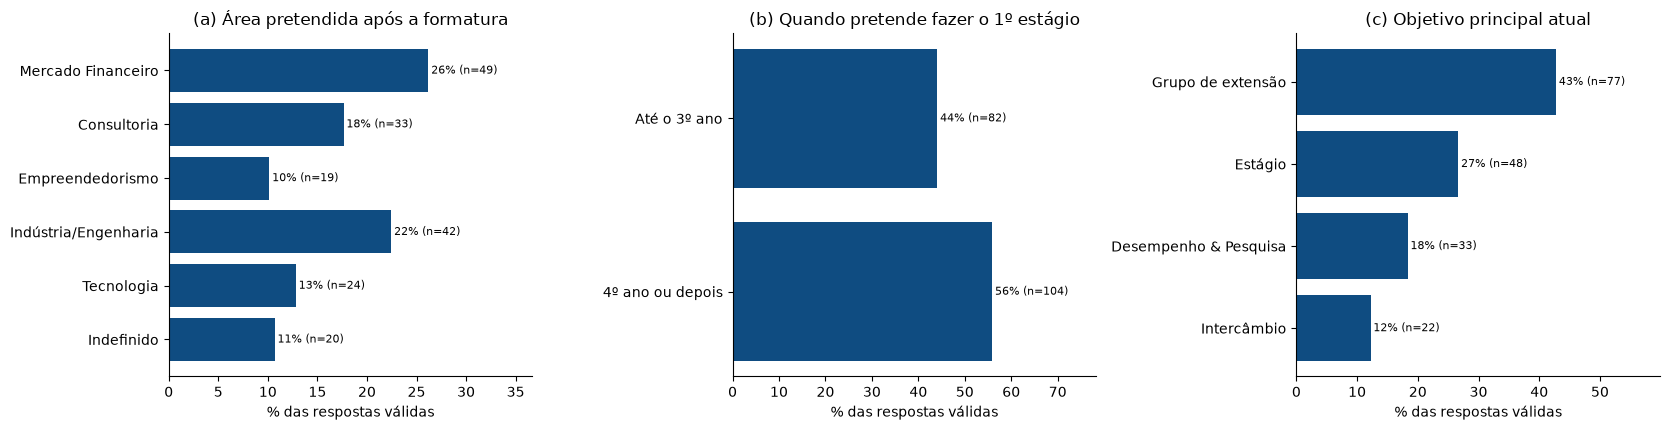

In [4]:
plot_category_distribution(df, [("area_pretendida", "(a) Área pretendida após a formatura"),
                                ("estagio_antecipado", "(b) Quando pretende fazer o 1º estágio"),
                                ("objetivo_grupo", "(c) Objetivo principal atual")],
                           FIG_DIR / "f3_fig01_distribuicao_variaveis_principais.png")

**Leitura.**

- **Área pretendida:** Mercado Financeiro é a mais citada (49 alunos; 26%), seguida de Indústria/Engenharia (42; 22%) e Consultoria (33; 18%). Só 20 alunos (11%) estão indefinidos.
- **Estágio:** 82 de 186 respondentes (44%) pretendem fazer o 1º estágio até o 3º ano e 104 (56%) só a partir do 4º. Como a amostra é jovem, isso é intenção, não fato.
- **Objetivo atual:** "Grupo de extensão" é o mais comum (77 de 180; 43%), à frente de Estágio (48; 27%). Intercâmbio tem 22 (12%) e Desempenho acadêmico e IC/Pesquisa juntos, 33 (18%).
- **Perfil da amostra:** 31 alunos no 1º ano (17%), 93 no 2º (50%) e 63 no 3º ano ou mais (34%); 108 (58%) estão em grupos de Consultoria & Negócios.
- **Base dos percentuais:** neste texto e na figura, os percentuais usam como base as respostas válidas (por exemplo, 180 no objetivo atual). A `f3_tab01` usa os 187 alunos como base, com a linha "Sem resposta", por isso alguns valores diferem um pouco (Grupo de extensão: 43% aqui, 41,2% na tabela).

## 3. P1 — A área pretendida está associada ao grupo de extensão e ao curso?

**(a) Pergunta e hipóteses.** Dois testes de associação.

- **P1a** — área pretendida × categoria do grupo:
  - $H_0$: a área pretendida é independente da categoria do grupo;
  - $H_1$: há associação.
- **P1b** — área pretendida × grande área do curso:
  - $H_0$: a área pretendida é independente da grande área do curso;
  - $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação. As premissas são duas: observações independentes (um aluno por linha) e no máximo cerca de 20% das caselas com frequência esperada abaixo de 5.

- Na P1a, Consultoria e Empreendedorismo foram somadas como área pretendida (tabela de agrupamentos).
- Na P1b, os 20 alunos "Indefinido" ficam de fora. Com eles, 28% das caselas ficam abaixo de 5; sem eles, 10%.

> **Conceito — resíduo padronizado ajustado.** O qui-quadrado diz *se* há associação, mas não *onde*. Para cada casela, o resíduo ajustado compara o observado com o esperado sob independência, em unidades de desvio-padrão: $r = (O - E) / \sqrt{E (1 - p_{\text{linha}})(1 - p_{\text{coluna}})}$. Sob $H_0$, ele segue aproximadamente uma normal padrão. Por isso, $|r| > 2$ indica uma casela com bem mais (r positivo) ou bem menos (r negativo) alunos do que o esperado.
>
> **Conceito — V de Cramér.** $V = \sqrt{\chi^2 / (n \cdot k)}$, com $k$ = min(linhas, colunas) − 1. Vai de 0 (nenhuma associação) a 1 (associação total). As referências de Cohen dependem do $k$ de cada tabela: para $k = 2$, 0,07 fraca, 0,21 moderada e 0,35 forte; para $k = 3$, 0,06 fraca, 0,17 moderada e 0,29 forte.

In [5]:
p1a_sample = analysis_sample(df, ["area_grupo", "categoria_grupo"])
p1a_observed, p1a_result = chi_square_association(p1a_sample, "categoria_grupo", "area_grupo")
p1b_sample = analysis_sample(df, ["area_grupo", "grande_area_curso"], exclude={"area_grupo": ["Indefinido"]})
p1b_observed, p1b_result = chi_square_association(p1b_sample, "grande_area_curso", "area_grupo")

p1_results = pd.concat({"P1a: área pretendida × categoria do grupo": p1a_result.iloc[:, 0],
                        "P1b: área pretendida × grande área do curso (sem Indefinido)": p1b_result.iloc[:, 0]},
                       axis=1).T.rename_axis("Teste")
p1a_observed.to_csv(TAB_DIR / "f3_tab03_p1_area_x_categoria.csv")
p1b_observed.to_csv(TAB_DIR / "f3_tab04_p1_area_x_grande_area.csv")
p1_results.to_csv(TAB_DIR / "f3_tab05_p1_qui_quadrado.csv")
p1_results

,Qui-quadrado (χ²),Graus de liberdade,p-valor,"V de Cramér (0 = nenhuma, 1 = total)",Menor frequência esperada,% de caselas com esperado < 5,Decisão (α = 5%)
Teste,,,,,,,
P1a: área pretendida × categoria do grupo,95.02,8,4.4e-17,0.504,3.64,20%,Rejeita H0
P1b: área pretendida × grande área do curso (sem Indefinido),60.43,12,1.9e-08,0.347,3.02,10%,Rejeita H0


In [6]:
print("P1a — contagens e % por categoria do grupo")
display(p1a_observed)
display(row_percentages(p1a_observed))
print("P1a — resíduos padronizados ajustados (|r| > 2 em destaque na leitura)")
p1a_residuals = standardized_residuals(p1a_observed)
p1a_residuals.to_csv(TAB_DIR / "f3_tab06_p1a_residuos.csv")
p1a_residuals

P1a — contagens e % por categoria do grupo


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,27,43,13,12,13
Engenharia,0,3,27,12,3
Mercado Financeiro,22,6,2,0,4


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,25.0,39.8,12.0,11.1,12.0
Engenharia,0.0,6.7,60.0,26.7,6.7
Mercado Financeiro,64.7,17.6,5.9,0.0,11.8


P1a — resíduos padronizados ajustados (|r| > 2 em destaque na leitura)


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,-0.44,4.28,-3.99,-0.82,0.69
Engenharia,-4.59,-3.63,6.92,3.18,-1.00
Mercado Financeiro,5.64,-1.46,-2.56,-2.47,0.22


In [7]:
print("P1b — contagens e % por grande área do curso")
display(p1b_observed)
display(row_percentages(p1b_observed))
p1b_residuals = standardized_residuals(p1b_observed)
p1b_residuals.to_csv(TAB_DIR / "f3_tab07_p1b_residuos.csv")
p1b_residuals

P1b — contagens e % por grande área do curso


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,12,15,12,1
Elétrica & Computação,11,10,6,15
"Mecânica, Mecatrônica & Naval",6,6,22,5
Produção,13,10,0,2
Outras Engenharias,7,11,2,1


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,30.0,37.5,30.0,2.5
Elétrica & Computação,26.2,23.8,14.3,35.7
"Mecânica, Mecatrônica & Naval",15.4,15.4,56.4,12.8
Produção,52.0,40.0,0.0,8.0
Outras Engenharias,33.3,52.4,9.5,4.8


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,0.10,1.00,0.81,-2.45
Elétrica & Computação,-0.52,-1.19,-1.88,4.56
"Mecânica, Mecatrônica & Naval",-2.19,-2.43,5.14,-0.32
Produção,2.70,1.04,-3.14,-0.98
Outras Engenharias,0.43,2.25,-1.77,-1.34


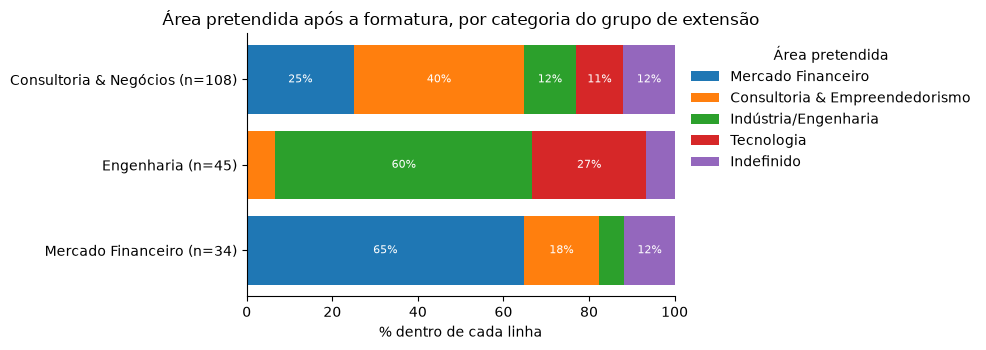

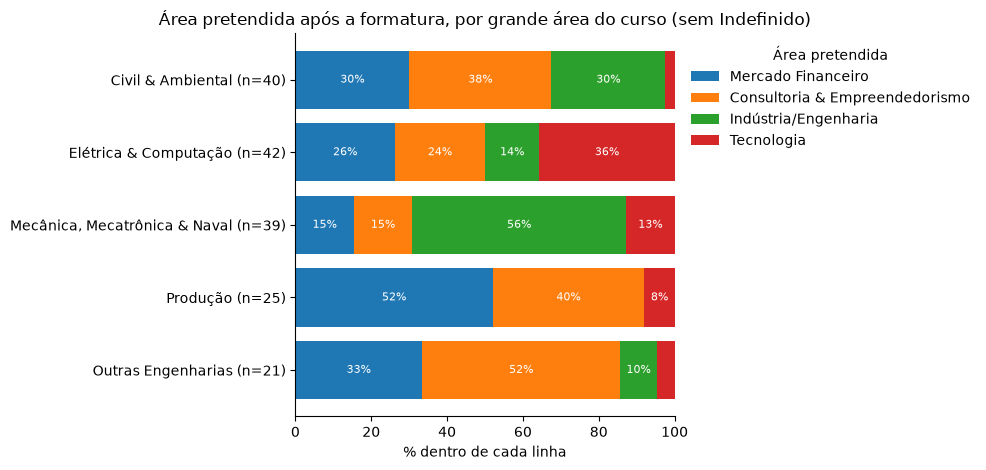

In [8]:
plot_stacked_shares(p1a_observed, "Área pretendida após a formatura, por categoria do grupo de extensão",
                    "Área pretendida", FIG_DIR / "f3_fig02_p1_area_por_categoria.png")
plot_stacked_shares(p1b_observed, "Área pretendida após a formatura, por grande área do curso (sem Indefinido)",
                    "Área pretendida", FIG_DIR / "f3_fig03_p1_area_por_grande_area.png")

**(c) Resultado.**

1. **P1a, área pretendida × categoria do grupo (n = 187):** χ²(8) = 95,0, p < 0,001, V de Cramér = 0,50, acima da referência de associação forte (0,35 para $k = 2$, tabela 3×5). A condição do teste é atendida no limite (20% das caselas com esperado abaixo de 5; menor esperado = 3,6). Caselas com |r| > 2:
   - **Mercado Financeiro:** 64,7% dos alunos desses grupos miram Mercado Financeiro (r = 5,64). Miram menos Indústria/Engenharia (5,9%; r = −2,56) e Tecnologia (0,0%; r = −2,47).
   - **Consultoria & Negócios:** 39,8% miram Consultoria & Empreendedorismo (r = 4,28) e só 12,0% miram Indústria/Engenharia (r = −3,99).
   - **Engenharia:** 60,0% miram Indústria/Engenharia (r = 6,92) e 26,7% miram Tecnologia (r = 3,18). Miram menos Mercado Financeiro (0,0%; r = −4,59) e Consultoria & Empreendedorismo (6,7%; r = −3,63).
2. **P1b, área pretendida × grande área do curso, sem Indefinido (n = 167):** χ²(12) = 60,4, p < 0,001, V de Cramér = 0,35, acima da referência de associação forte (0,29 para $k = 3$, tabela 5×4). A condição do teste é atendida (10% das caselas com esperado abaixo de 5; menor esperado = 3,0). Caselas com |r| > 2:
   - **Mecânica, Mecatrônica & Naval:** 56,4% miram Indústria/Engenharia (r = 5,14). Miram menos Mercado Financeiro (15,4%; r = −2,19) e Consultoria & Empreendedorismo (15,4%; r = −2,43).
   - **Elétrica & Computação:** 35,7% miram Tecnologia (r = 4,56).
   - **Produção:** 52,0% miram Mercado Financeiro (r = 2,70) e nenhum aluno mira Indústria/Engenharia (0,0%; r = −3,14).
   - **Civil & Ambiental:** só 2,5% miram Tecnologia (r = −2,45).
   - **Outras Engenharias:** 52,4% miram Consultoria & Empreendedorismo (r = 2,25).

**(d)** Figuras `f3_fig02` e `f3_fig03`, tabelas `f3_tab03` a `f3_tab07`.

**(e) Conclusão para o relatório.** A área pretendida está fortemente associada à categoria do grupo (χ², p < 0,001; V = 0,50) e à grande área do curso (χ², p < 0,001; V = 0,35). Quem está em grupos de Mercado Financeiro tende a mirar Mercado Financeiro (65%), Consultoria & Negócios mira Consultoria & Empreendedorismo (40%) e Engenharia mira Indústria/Engenharia (60%); entre os cursos, destacam-se Mecânica (Indústria/Engenharia) e Elétrica & Computação (Tecnologia). Há possível autosseleção: o aluno pode ter escolhido o grupo pela área que já mirava, então a associação não mostra que o grupo molda a área pretendida.

## 4. P2 — A motivação para entrar no grupo se reflete na área pretendida?

**(a) Pergunta e hipóteses.**

- $H_0$: a área pretendida é independente da motivação de ingresso;
- $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação, com resíduos ajustados.

- "Outros" (Networking, 6, e Indicação de amigos, 1) fica fora do teste: com essa linha, 40% das caselas ficam abaixo de 5; sem ela, 20%. Por isso n = 180.
- Consultoria e Empreendedorismo continuam somadas, como na P1.

In [9]:
p2_sample = analysis_sample(df, ["motivacao_grupo", "area_grupo"], exclude={"motivacao_grupo": ["Outros"]})
p2_observed, p2_result = chi_square_association(p2_sample, "motivacao_grupo", "area_grupo")
p2_observed.to_csv(TAB_DIR / "f3_tab08_p2_motivacao_x_area.csv")
p2_result.to_csv(TAB_DIR / "f3_tab09_p2_qui_quadrado.csv")
display(p2_observed)
display(row_percentages(p2_observed))
p2_result

area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,6,11,14,7,8
Aprendizado técnico (hardskills),20,9,10,5,3
"Desenvolvimento pessoal, comunicação e liderança (softskills)",5,15,8,6,6
Interesse pela temática e objetivos do grupo,16,14,10,5,2


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,13.0,23.9,30.4,15.2,17.4
Aprendizado técnico (hardskills),42.6,19.1,21.3,10.6,6.4
"Desenvolvimento pessoal, comunicação e liderança (softskills)",12.5,37.5,20.0,15.0,15.0
Interesse pela temática e objetivos do grupo,34.0,29.8,21.3,10.6,4.3


,Teste de associação
Qui-quadrado (χ²),22.21
Graus de liberdade,12
p-valor,0.0352
"V de Cramér (0 = nenhuma, 1 = total)",0.203
Menor frequência esperada,4.22
% de caselas com esperado < 5,20%
Decisão (α = 5%),Rejeita H0


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,-2.34,-0.58,1.32,0.57,1.75
Aprendizado técnico (hardskills),2.99,-1.45,-0.39,-0.51,-1.08
"Desenvolvimento pessoal, comunicação e liderança (softskills)",-2.22,1.66,-0.57,0.48,1.04
Interesse pela temática e objetivos do grupo,1.44,0.46,-0.39,-0.51,-1.64


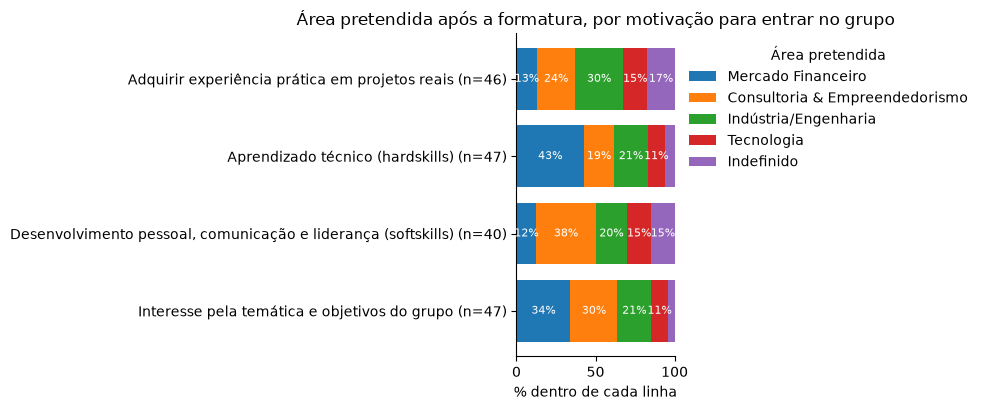

In [10]:
p2_residuals = standardized_residuals(p2_observed)
p2_residuals.to_csv(TAB_DIR / "f3_tab10_p2_residuos.csv")
display(p2_residuals)
plot_stacked_shares(p2_observed, "Área pretendida após a formatura, por motivação para entrar no grupo",
                    "Área pretendida", FIG_DIR / "f3_fig04_p2_area_por_motivacao.png")

**(c) Resultado.**

- **Teste (n = 180):** χ²(12) = 22,2, p = 0,035, V de Cramér = 0,20, acima da referência de associação moderada (0,17 para $k = 3$, tabela 4×5) e abaixo da forte (0,29). Rejeita-se $H_0$ ao nível de 5%. A condição do teste é atendida no limite (20% das caselas com esperado abaixo de 5; menor esperado = 4,2).
- **Caselas com |r| > 2:**
  - **Aprendizado técnico (hardskills):** 42,6% miram Mercado Financeiro (r = 2,99);
  - **Adquirir experiência prática em projetos reais:** só 13,0% miram Mercado Financeiro (r = −2,34);
  - **Desenvolvimento pessoal, comunicação e liderança:** só 12,5% miram Mercado Financeiro (r = −2,22).
- Nas demais caselas, os resíduos ficam dentro de ±2.

**(d)** Figura `f3_fig04`, tabelas `f3_tab08` a `f3_tab10`.

**(e) Conclusão para o relatório.** Há associação estatisticamente significativa entre a motivação de ingresso e a área pretendida (χ², p = 0,035), com associação moderada (V = 0,20; mais perto da referência moderada, 0,17, que da forte, 0,29), de magnitude modesta, e o p-valor fica perto do limite de 5%, então o resultado deve ser lido com cautela. A diferença concentra-se em Mercado Financeiro: quem entrou por aprendizado técnico mira essa área com mais frequência (43%) do que quem entrou por experiência prática (13%) ou por desenvolvimento pessoal (13%). Nas outras áreas, não há desvio claro em relação à independência.

## 5. P3 — Alunos de alguma categoria de grupo pretendem antecipar o 1º estágio?

**(a) Pergunta e hipóteses.**

- $H_0$: pretender o 1º estágio até o 3º ano é independente da categoria do grupo;
- $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação numa tabela 3 × 2 (n = 186, sem a resposta "Não pretendo realizar estágio"). Nenhuma casela tem esperado abaixo de 5.

**Atenção:** como a maioria ainda está no 1º ou 2º ano, a variável mede **intenção**. A pergunta é "quem *pretende* estagiar mais cedo", não "quem estagiou mais cedo".

estagio_antecipado,Até o 3º ano,4º ano ou depois
categoria_grupo,,
Consultoria & Negócios,54,54
Engenharia,15,29
Mercado Financeiro,13,21


estagio_antecipado,Até o 3º ano,4º ano ou depois
categoria_grupo,,
Consultoria & Negócios,50.0,50.0
Engenharia,34.1,65.9
Mercado Financeiro,38.2,61.8


,Teste de associação
Qui-quadrado (χ²),3.79
Graus de liberdade,2
p-valor,0.1505
"V de Cramér (0 = nenhuma, 1 = total)",0.143
Menor frequência esperada,14.99
% de caselas com esperado < 5,0%
Decisão (α = 5%),Não rejeita H0


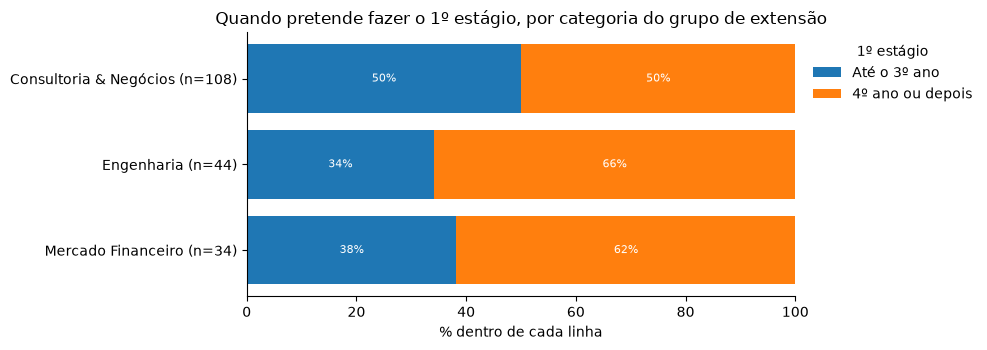

In [11]:
p3_sample = analysis_sample(df, ["categoria_grupo", "estagio_antecipado"])
p3_observed, p3_result = chi_square_association(p3_sample, "categoria_grupo", "estagio_antecipado")
p3_observed.to_csv(TAB_DIR / "f3_tab11_p3_categoria_x_estagio.csv")
p3_result.to_csv(TAB_DIR / "f3_tab12_p3_qui_quadrado.csv")
display(p3_observed)
display(row_percentages(p3_observed))
display(p3_result)
plot_stacked_shares(p3_observed, "Quando pretende fazer o 1º estágio, por categoria do grupo de extensão",
                    "1º estágio", FIG_DIR / "f3_fig05_p3_estagio_por_categoria.png")

**(c) Resultado.**

- **Teste (n = 186):** χ²(2) = 3,79, p = 0,15, V de Cramér = 0,14, entre as referências de associação fraca (0,10) e moderada (0,30) para $k = 1$ (tabela 3×2). Não se rejeita $H_0$ ao nível de 5%. A condição do teste é atendida (0% das caselas com esperado abaixo de 5; menor esperado = 15,0).
- **Proporção que pretende estagiar até o 3º ano:**
  - Consultoria & Negócios: 50,0% (54 de 108);
  - Mercado Financeiro: 38,2% (13 de 34);
  - Engenharia: 34,1% (15 de 44).

**(d)** Figura `f3_fig05`, tabelas `f3_tab11` e `f3_tab12`.

**(e) Conclusão para o relatório.** Não há evidência estatística de associação entre a categoria do grupo e a intenção de fazer o 1º estágio até o 3º ano (χ², p = 0,15). Os grupos de Consultoria & Negócios têm a maior proporção (50%), contra 38% em Mercado Financeiro e 34% em Engenharia, mas essa diferença pode ser acaso amostral. As diferenças entre 34% e 50% são apenas descritivas: o teste não detectou associação, e ausência de evidência não é evidência de ausência. O resultado fala de **intenção**, não de quem de fato estagiou mais cedo.

## 6. P4 — O objetivo principal muda ao longo da graduação?

**(a) Pergunta e hipóteses.**

- $H_0$: o objetivo principal atual é independente do ano na Poli;
- $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação (n = 180, sem os 7 objetivos ausentes), com resíduos ajustados.

- Os anos 3, 4 e 5 foram somados, porque só 9 alunos estão no 4º ou 5º ano.
- "Desempenho acadêmico" e "Iniciação científica" foram somados (n = 6 em Iniciação científica). Com 5 objetivos, 33% das caselas ficam abaixo de 5; com 4, 8%.

**Atenção:** os dados são de um único momento. Compararam-se **turmas diferentes** (quem está hoje no 1º, no 2º e no 3º ano), não as mesmas pessoas ao longo do tempo. A "migração" é uma leitura entre turmas.

In [12]:
p4_sample = analysis_sample(df, ["objetivo_grupo", "ano_poli_grupo"])
p4_observed, p4_result = chi_square_association(p4_sample, "ano_poli_grupo", "objetivo_grupo")
p4_observed.to_csv(TAB_DIR / "f3_tab13_p4_objetivo_x_ano.csv")
p4_result.to_csv(TAB_DIR / "f3_tab14_p4_qui_quadrado.csv")
display(p4_observed)
display(row_percentages(p4_observed))
p4_result

objetivo_grupo,Grupo de extensão,Estágio,Desempenho & Pesquisa,Intercâmbio
ano_poli_grupo,,,,
1º ano,16,5,5,2
2º ano,49,14,14,12
3º ano ou mais,12,29,14,8


objetivo_grupo,Grupo de extensão,Estágio,Desempenho & Pesquisa,Intercâmbio
ano_poli_grupo,,,,
1º ano,57.1,17.9,17.9,7.1
2º ano,55.1,15.7,15.7,13.5
3º ano ou mais,19.0,46.0,22.2,12.7


,Teste de associação
Qui-quadrado (χ²),28.02
Graus de liberdade,6
p-valor,9.3e-05
"V de Cramér (0 = nenhuma, 1 = total)",0.279
Menor frequência esperada,3.42
% de caselas com esperado < 5,8%
Decisão (α = 5%),Rejeita H0


objetivo_grupo,Grupo de extensão,Estágio,Desempenho & Pesquisa,Intercâmbio
ano_poli_grupo,,,,
1º ano,1.67,-1.15,-0.07,-0.89
2º ano,3.29,-3.28,-0.89,0.51
3º ano ou mais,-4.72,4.31,0.99,0.14


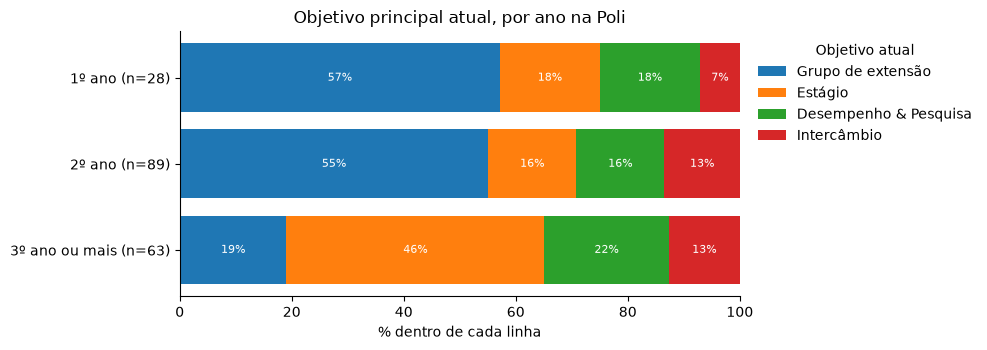

In [13]:
p4_residuals = standardized_residuals(p4_observed)
p4_residuals.to_csv(TAB_DIR / "f3_tab15_p4_residuos.csv")
display(p4_residuals)
plot_stacked_shares(p4_observed, "Objetivo principal atual, por ano na Poli", "Objetivo atual",
                    FIG_DIR / "f3_fig06_p4_objetivo_por_ano.png")

**(c) Resultado.**

- **Teste (n = 180):** χ²(6) = 28,0, p < 0,001, V de Cramér = 0,28, entre as referências de associação moderada (0,21) e forte (0,35) para $k = 2$ (tabela 3×4). Rejeita-se $H_0$ ao nível de 5%. A condição do teste é atendida (8% das caselas com esperado abaixo de 5; menor esperado = 3,4).
- **Caselas com |r| > 2:**
  - **3º ano ou mais, Grupo de extensão:** só 19,0% (r = −4,72);
  - **3º ano ou mais, Estágio:** 46,0% (r = 4,31);
  - **2º ano, Grupo de extensão:** 55,1% (r = 3,29);
  - **2º ano, Estágio:** 15,7% (r = −3,28).
- No 1º ano, os resíduos ficam dentro de ±2 (Grupo de extensão: 57,1%, r = 1,67), e "Desempenho & Pesquisa" e "Intercâmbio" não têm casela com |r| > 2.
- **Sobre a coluna antiga:** o mesmo teste (4 objetivos agrupados × 3 anos), calculado fora deste notebook sobre o arquivo antigo de 24/11, com `anos_de_poli` desalinhada de `ano_ingresso`, daria χ²(6) = 12,28 e p = 0,056, ou seja, a associação não chegaria a 5%. Com a coluna corrigida, p < 0,001. Esse é o motivo de o parquet ter sido gerado de novo. (A preparação atual recusa o arquivo antigo, por isso o cálculo não está neste notebook.)

**(d)** Figura `f3_fig06`, tabelas `f3_tab13` a `f3_tab15`.

**(e) Conclusão para o relatório.** Há associação estatisticamente significativa entre o ano na Poli e o objetivo principal atual (χ², p < 0,001), de magnitude moderada a forte (V = 0,28). Entre as turmas, "Grupo de extensão" pesa mais no 1º e no 2º ano (57% e 55%) e "Estágio" passa a ser o objetivo mais citado no 3º ano ou mais (46%, contra 18% no 1º e 16% no 2º ano). Os dados são de um único momento e comparam turmas diferentes, então isso é uma leitura entre turmas, não o acompanhamento das mesmas pessoas ao longo do tempo.

## 7. P6 — Quem mira Mercado Financeiro ou Consultoria valoriza mais a média e tem média maior?

**(a) Pergunta e hipóteses.** Seja $\mu_j$ a média da variável entre os alunos que pretendem a área $j$ (6 áreas, sem agrupar: a ANOVA não tem a restrição de caselas do qui-quadrado). Duas ANOVAs:

- **importância da média ponderada** (escala 1–5): $H_0$: $\mu_1 = \dots = \mu_6$; $H_1$: ao menos uma média difere;
- **média ponderada** (ponto médio da faixa): mesmas hipóteses.

A hipótese do guia vira um **contraste definido antes de ver os resultados**: a média simples de {Mercado Financeiro, Consultoria} menos a média simples das outras 4 áreas. $H_1$ do guia: o contraste é positivo.

**(b) Teste e premissas.** ANOVA de 1 fator, com:

- teste de Bartlett para a igualdade das variâncias;
- η² como tamanho de efeito;
- Scheffé para o contraste e para todos os pares (só na importância da média).

Regra 3 do guia: a média ponderada numérica é uma aproximação pelo ponto médio das faixas. Por isso, o resultado é checado também na versão ordinal, com um qui-quadrado de 3 faixas (abaixo de 7,0; 7,0 a 7,9; 8,0 ou mais) × área agrupada.

A Frente 1 (P6) já mostrou que o **objetivo atual** está associado a 27% da variação da importância dada à média. Aqui a pergunta é se a **área pretendida** acrescenta algo, olhada sozinha.

> **Conceito — contraste de Scheffé.** Um contraste é uma combinação das médias com pesos que somam zero, por exemplo $L = \tfrac{1}{2}\mu_{MF} + \tfrac{1}{2}\mu_{C} - \tfrac{1}{4}(\mu_{E} + \mu_{I} + \mu_{T} + \mu_{Ind})$. O teste de Scheffé controla o erro para qualquer quantidade de contrastes, inclusive os escolhidos depois de olhar os dados. Por isso ele também é usado nos pares.

In [14]:
p6_outcomes = {"importancia_media": "Importância da média ponderada (1–5)",
               "media_ponderada_num": "Média ponderada (ponto médio da faixa)"}
p6_anova = pd.concat([one_way_anova(df, col, "area_pretendida", title=f"ANOVA de 1 fator: {label} por área pretendida")
                      for col, label in p6_outcomes.items()], axis=1).T
p6_anova.to_csv(TAB_DIR / "f3_tab16_p6_anova.csv")
p6_anova

,F,gl (fator; resíduo),p-valor,η² (variância explicada),Decisão (α = 5%),Bartlett (χ²),p Bartlett,Variâncias homogêneas?
ANOVA de 1 fator: Importância da média ponderada (1–5) por área pretendida,2.74,5; 181,0.0207,0.07,Rejeita H0,4.85,0.4348,Sim (não rejeita H0)
ANOVA de 1 fator: Média ponderada (ponto médio da faixa) por área pretendida,0.34,5; 178,0.8879,0.009,Não rejeita H0,10.46,0.0631,Sim (não rejeita H0)


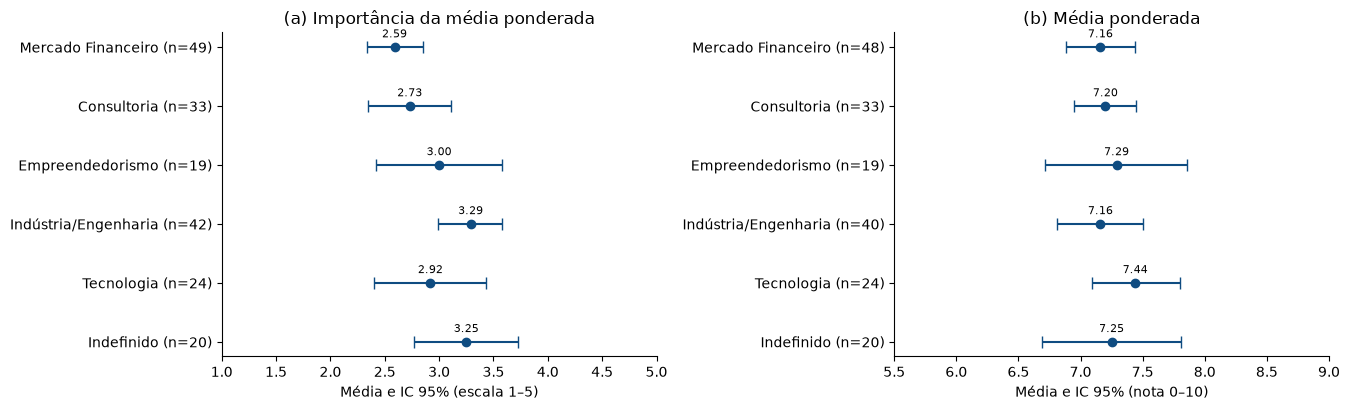

Importância da média ponderada (1–5)                      \
                                                        n Média Desvio-padrão   
Área pretendida                                                                 
Mercado Financeiro                                     49  2.59          0.89   
Consultoria                                            33  2.73          1.07   
Empreendedorismo                                       19  3.00          1.20   
Indústria/Engenharia                                   42  3.29          0.94   
Tecnologia                                             24  2.92          1.21   
Indefinido                                             20  3.25          1.02   

                                            \
                     IC 95% inf IC 95% sup   
Área pretendida                              
Mercado Financeiro         2.34       2.85   
Consultoria                2.35       3.11   
Empreendedorismo           2.42       3.58   
Indústria/Engenharia       2.99       3.58   
Tecnologia                 2.40       3.43   
Indefinido                 2.77       3.73   

                     Média ponderada (ponto médio da faixa)        \
                                                          n Média   
Área pretendida                                                     
Mercado Financeiro                                       48  7.16   
Consultoria                                              33  7.20   
Empreendedorismo                                         19  7.29   
Indústria/Engenharia                                     40  7.16   
Tecnologia                                               24  7.44   
Indefinido                                               20  7.25   

                                                          
                     Desvio-padrão IC 95% inf IC 95% sup  
Área pretendida                                           
Mercado Financeiro            0.97       6.88       7.44  
Consultoria                   0.71       6.95       7.45  
Empreendedorismo              1.19       6.71       7.86  
Indústria/Engenharia          1.09       6.81       7.50  
Tecnologia                    0.85       7.09       7.80  
Indefinido                    1.21       6.69       7.81

In [15]:
p6_means = {label: group_means(df, col, "area_pretendida", "Área pretendida") for col, label in p6_outcomes.items()}
pd.concat(p6_means, axis=1).to_csv(TAB_DIR / "f3_tab17_p6_medias.csv")
plot_means_panels([(p6_means[p6_outcomes["importancia_media"]], CAREER_ORDER, "(a) Importância da média ponderada",
                    "Média e IC 95% (escala 1–5)", (1, 5)),
                   (p6_means[p6_outcomes["media_ponderada_num"]], CAREER_ORDER, "(b) Média ponderada",
                    "Média e IC 95% (nota 0–10)", (5.5, 9))],
                  FIG_DIR / "f3_fig07_p6_medias_por_area.png")
pd.concat(p6_means, axis=1)

In [16]:
p6_scheffe = pd.concat({
    "Importância da média — contraste a priori": scheffe_contrasts(df, "importancia_media", "area_pretendida",
                                                                    CAREER_CONTRASTS),
    "Média ponderada — contraste a priori": scheffe_contrasts(df, "media_ponderada_num", "area_pretendida",
                                                              CAREER_CONTRASTS),
    "Importância da média — todos os pares": scheffe_contrasts(df, "importancia_media", "area_pretendida"),
}, names=["Análise", "Contraste"])
p6_scheffe.to_csv(TAB_DIR / "f3_tab18_p6_scheffe.csv")
p6_scheffe

Estimativa (diferença)  \
Análise                                   Contraste                                                                    
Importância da média — contraste a priori Média simples de {Mercado Financeiro, Consultor...                   -0.45   
Média ponderada — contraste a priori      Média simples de {Mercado Financeiro, Consultor...                   -0.11   
Importância da média — todos os pares     Mercado Financeiro − Consultoria                                     -0.14   
                                          Mercado Financeiro − Empreendedorismo                                -0.41   
                                          Mercado Financeiro − Indústria/Engenharia                            -0.69   
                                          Mercado Financeiro − Tecnologia                                      -0.32   
                                          Mercado Financeiro − Indefinido                                      -0.66   
                                          Consultoria − Empreendedorismo                                       -0.27   
                                          Consultoria − Indústria/Engenharia                                   -0.56   
                                          Consultoria − Tecnologia                                             -0.19   
                                          Consultoria − Indefinido                                             -0.52   
                                          Empreendedorismo − Indústria/Engenharia                              -0.29   
                                          Empreendedorismo − Tecnologia                                         0.08   
                                          Empreendedorismo − Indefinido                                        -0.25   
                                          Indústria/Engenharia − Tecnologia                                     0.37   
                                          Indústria/Engenharia − Indefinido                                     0.04   
                                          Tecnologia − Indefinido                                              -0.33   

                                                                                             IC 95% de Scheffé  \
Análise                                   Contraste                                                              
Importância da média — contraste a priori Média simples de {Mercado Financeiro, Consultor...     [-0.98; 0.07]   
Média ponderada — contraste a priori      Média simples de {Mercado Financeiro, Consultor...     [-0.62; 0.41]   
Importância da média — todos os pares     Mercado Financeiro − Consultoria                       [-0.91; 0.64]   
                                          Mercado Financeiro − Empreendedorismo                  [-1.34; 0.52]   
                                          Mercado Financeiro − Indústria/Engenharia              [-1.42; 0.03]   
                                          Mercado Financeiro − Tecnologia                        [-1.18; 0.54]   
                                          Mercado Financeiro − Indefinido                        [-1.57; 0.26]   
                                          Consultoria − Empreendedorismo                         [-1.27; 0.72]   
                                          Consultoria − Indústria/Engenharia                     [-1.36; 0.24]   
                                          Consultoria − Tecnologia                               [-1.12; 0.74]   
                                          Consultoria − Indefinido                               [-1.50; 0.46]   
                                          Empreendedorismo − Indústria/Engenharia                [-1.24; 0.67]   
                                          Empreendedorismo − Tecnologia                          [-0.98; 1.14]   
                                          Empreendedorismo − Indefinido                          [-1.36

In [17]:
p6_ordinal_sample = analysis_sample(df, ["area_grupo", "faixa_media"])
p6_ordinal_observed, p6_ordinal_result = chi_square_association(p6_ordinal_sample, "area_grupo", "faixa_media")
p6_ordinal_result.to_csv(TAB_DIR / "f3_tab19_p6_ordinal.csv")
display(p6_ordinal_observed)
p6_ordinal_result

faixa_media,"Abaixo de 7,0","7,0 a 7,9","8,0 ou mais"
area_grupo,,,
Mercado Financeiro,21,18,9
Consultoria & Empreendedorismo,17,26,9
Indústria/Engenharia,17,13,10
Tecnologia,7,11,6
Indefinido,9,4,7


,Teste de associação
Qui-quadrado (χ²),8.43
Graus de liberdade,8
p-valor,0.3925
"V de Cramér (0 = nenhuma, 1 = total)",0.151
Menor frequência esperada,4.46
% de caselas com esperado < 5,7%
Decisão (α = 5%),Não rejeita H0


**(c) Resultado.**

- **Importância da média (n = 187):** F(5; 181) = 2,74, p = 0,021, η² = 0,07, ou seja, a área pretendida está associada a 7% da variação, um efeito pequeno a moderado pelas referências de Cohen para η² (0,01 pequeno, 0,06 médio, 0,14 grande). O teste de Bartlett não rejeita variâncias iguais (p = 0,43). Rejeita-se $H_0$ ao nível de 5%.
- **Médias da importância:** Mercado Financeiro tem a **menor** (2,59) e Consultoria a segunda menor (2,73); Indústria/Engenharia tem a maior (3,29), seguida de Indefinido (3,25).
- **Contraste a priori** {Mercado Financeiro, Consultoria} − demais áreas: −0,45 ponto (IC de Scheffé: −0,98 a 0,07; p = 0,14). Ele sai **negativo e não significativo**, ao contrário da $H_1$ do guia.
- **Scheffé nos 15 pares:** nenhum par difere ao nível de 5%. O mais próximo é Mercado Financeiro × Indústria/Engenharia (−0,69; p = 0,071). A ANOVA global é significativa, mas o Scheffé, mais conservador, não localiza o par responsável.
- **Média ponderada (n = 184):** F(5; 178) = 0,34, p = 0,89, η² = 0,009. As médias ficam entre 7,16 e 7,44. O Bartlett (p = 0,063) não rejeita variâncias iguais, mas fica perto do limite. O contraste a priori é −0,11 (IC de Scheffé: −0,62 a 0,41; p = 0,99).
- **Checagem ordinal (n = 184):** χ²(8) = 8,43, p = 0,39, V de Cramér = 0,15, entre as referências de associação pequena (0,07) e moderada (0,21) para $k = 2$ (tabela 5×3). Não se rejeita $H_0$. A condição do teste é atendida (7% das caselas com esperado abaixo de 5; menor esperado = 4,5).

**(d)** Figura `f3_fig07`, tabelas `f3_tab16` a `f3_tab19`.

**(e) Conclusão para o relatório.** A área pretendida se associa à importância dada à média (ANOVA, p = 0,021; η² = 0,07, efeito pequeno a moderado), mas no sentido contrário ao da hipótese do guia: quem mira Mercado Financeiro (2,59) ou Consultoria (2,73) dá, em média, menos importância à média do que quem mira Indústria/Engenharia (3,29). O contraste a priori não é significativo (p = 0,14), o Scheffé não aponta nenhum par, e a média ponderada em si não difere entre as áreas (p = 0,89; ordinal, p = 0,39). A associação é bem menor que a do objetivo atual na Frente 1 (η² = 0,27).

## 8. P7 — Modelo explicativo: o que se associa à intenção de antecipar o 1º estágio?

**(a) Objetivo e hipóteses.** A resposta é $Y$ = 1 se o aluno pretende fazer o 1º estágio até o 3º ano, e 0 se pretende no 4º ano ou depois. O modelo completo foi definido antes de ver os resultados, com 6 blocos de preditores: categoria do grupo, grande área do curso, ano na Poli, objetivo atual, tempo no grupo e ln(horas semanais).

- Para cada bloco: $H_0$: os coeficientes do bloco são todos zero (dados os demais); $H_1$: ao menos um é diferente de zero.

**(b) Método e premissas.** Regressão linear múltipla de uma resposta 0/1, chamada **modelo de probabilidade linear**: o valor previsto é lido como uma probabilidade, e cada β é uma diferença em **pontos percentuais**. Etapas:

1. eliminação para trás por F parcial: a cada passo, sai o bloco de maior p, se p ≥ 0,05;
2. F parcial conjunto entre o modelo completo e o final;
3. coeficientes com IC 95%;
4. perfis definidos a priori (cada ano × cada grande área).

O método tem limitações conhecidas, que são declaradas:

- as previsões podem sair do intervalo de 0 a 100%;
- a variância dos resíduos não é constante por construção, já que $Y$ só vale 0 ou 1;
- os resíduos não são normais.

Com n = 179, os testes F continuam aproximadamente válidos. A regressão logística seria o modelo natural, mas está fora dos métodos da disciplina.

> **Conceito — efeito mecânico do ano.** A resposta vale 1 para quem pretende estagiar antes do 3º ano ou no 3º ano. Quem já está no 4º ano ou depois e ainda não estagiou não pode mais pretender fazê-lo "até o 3º ano". Para quem está no 3º ano, a janela se reduz ao ano corrente. A categoria "3º ano ou mais" mistura os dois casos. O ano entra no modelo principalmente como **controle** dessa restrição. A pergunta de interesse é se grupo, curso e objetivo acrescentam algo **dado o ano**.

In [18]:
p7_data = analysis_sample(df, REGRESSION_COLUMNS)
print(f"n do modelo: {len(p7_data)}")
print("Proporção que pretende estagiar até o 3º ano, por ano na Poli:")
display(p7_data.groupby("ano_poli_grupo", observed=True)["estagio_ate_3ano"].agg(["mean", "size"]).round(2))

p7_steps, p7_final, p7_kept = backward_elimination(p7_data, "estagio_ate_3ano", REGRESSION_BLOCKS)
p7_steps.to_csv(TAB_DIR / "f3_tab20_p7_eliminacao_f_parcial.csv")
p7_steps

n do modelo: 179
Proporção que pretende estagiar até o 3º ano, por ano na Poli:


,mean,size
ano_poli_grupo,,
1º ano,0.75,28
2º ano,0.53,88
3º ano ou mais,0.14,63


,Nº de variáveis no modelo,Variável com maior p,F parcial,gl,p parcial,Decisão,R² ajustado
Passo,,,,,,,
1,6,Objetivo atual,1.28,3; 163,0.2827,"Remover (p ≥ 0,05)",0.275
2,5,Tempo no grupo,1.65,3; 166,0.1790,"Remover (p ≥ 0,05)",0.272
3,4,Categoria do grupo,2.46,2; 169,0.0887,"Remover (p ≥ 0,05)",0.263
4,3,Horas semanais (log),3.85,1; 171,0.0514,"Remover (p ≥ 0,05)",0.251
5,2,Grande área do curso,3.42,4; 172,0.0102,"Manter todas (p < 0,05)",0.238


In [19]:
p7_full = fit_ols(p7_data, "estagio_ate_3ano", REGRESSION_BLOCKS)
display(joint_partial_f_test(p7_full, p7_final, "Modelo completo vs. modelo final"))
print("Blocos mantidos:", p7_kept)
model_summary(p7_final)

,Modelo completo vs. modelo final
F parcial,1.98
gl,9; 163
p-valor,0.0448
Decisão (α = 5%),Rejeita H0


Blocos mantidos: ['Grande área do curso', 'Ano na Poli']


,Ajuste do modelo
n,179
R²,0.264
R² ajustado,0.238
F global,10.28
gl (modelo; resíduo),6; 172
p-valor do F global,1.0e-09
Erro-padrão residual,0.433


In [20]:
p7_coefficients = coefficient_table(p7_final, REGRESSION_LABELS)
p7_coefficients.to_csv(TAB_DIR / "f3_tab21_p7_coeficientes.csv")
p7_coefficients

,β (estimativa),Erro-padrão,t,p-valor,IC 95% inf,IC 95% sup
Intercepto (perfil com todas as categorias de referência),0.798,0.106,7.49,3.4e-12,0.587,1.008
Área do curso: Elétrica & Computação (vs. Civil & Ambiental),0.044,0.092,0.48,0.6346,-0.138,0.225
"Área do curso: Mecânica, Mecatrônica & Naval (vs. Civil & Ambiental)",-0.234,0.098,-2.39,0.0178,-0.428,-0.041
Área do curso: Produção (vs. Civil & Ambiental),0.135,0.106,1.27,0.2063,-0.075,0.344
Área do curso: Outras Engenharias (vs. Civil & Ambiental),-0.015,0.116,-0.13,0.8991,-0.245,0.215
Ano: 2º ano (vs. 1º ano),-0.264,0.097,-2.73,0.0070,-0.456,-0.073
Ano: 3º ano ou mais (vs. 1º ano),-0.623,0.100,-6.21,3.8e-09,-0.820,-0.425


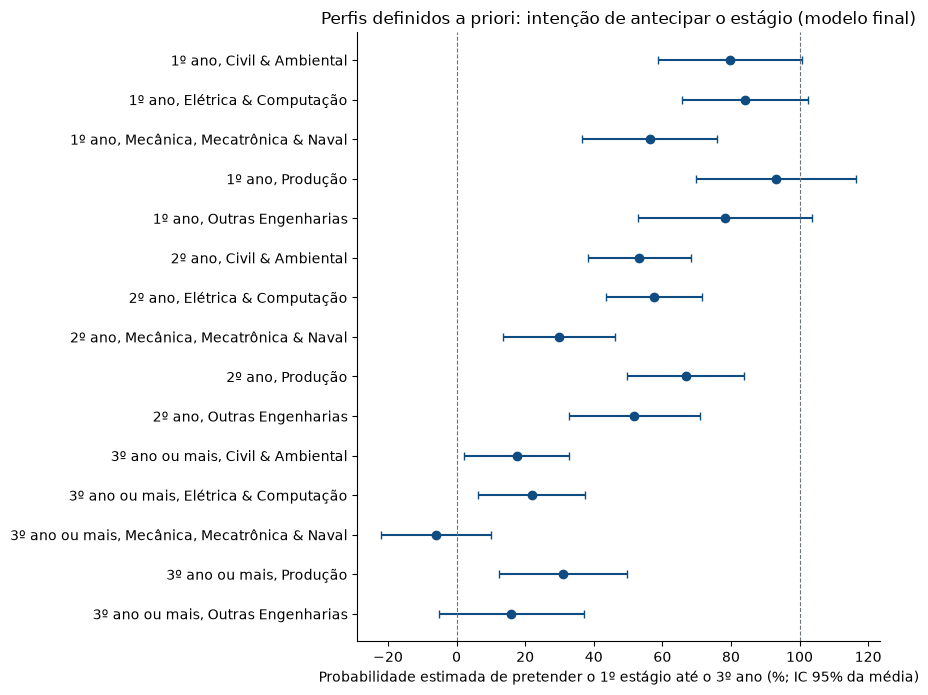

,Valor estimado (média do perfil),IC 95% da média,IP 95% individual
Cenário,,,
"1º ano, Civil & Ambiental",0.80,[0.59; 1.01],[-0.08; 1.68]
"1º ano, Elétrica & Computação",0.84,[0.66; 1.02],[-0.03; 1.72]
"1º ano, Mecânica, Mecatrônica & Naval",0.56,[0.37; 0.76],[-0.31; 1.44]
"1º ano, Produção",0.93,[0.70; 1.17],[0.05; 1.82]
"1º ano, Outras Engenharias",0.78,[0.53; 1.04],[-0.11; 1.68]
"2º ano, Civil & Ambiental",0.53,[0.38; 0.68],[-0.34; 1.40]
"2º ano, Elétrica & Computação",0.58,[0.44; 0.72],[-0.29; 1.44]
"2º ano, Mecânica, Mecatrônica & Naval",0.30,[0.14; 0.46],[-0.57; 1.17]
"2º ano, Produção",0.67,[0.50; 0.84],[-0.20; 1.54]


In [21]:
p7_scenarios = build_scenarios(df)
p7_predictions = predict_scenarios(p7_final, p7_scenarios)
p7_predictions.to_csv(TAB_DIR / "f3_tab22_p7_cenarios.csv")
plot_scenario_probabilities(p7_final, p7_scenarios, FIG_DIR / "f3_fig08_p7_cenarios.png")
p7_predictions

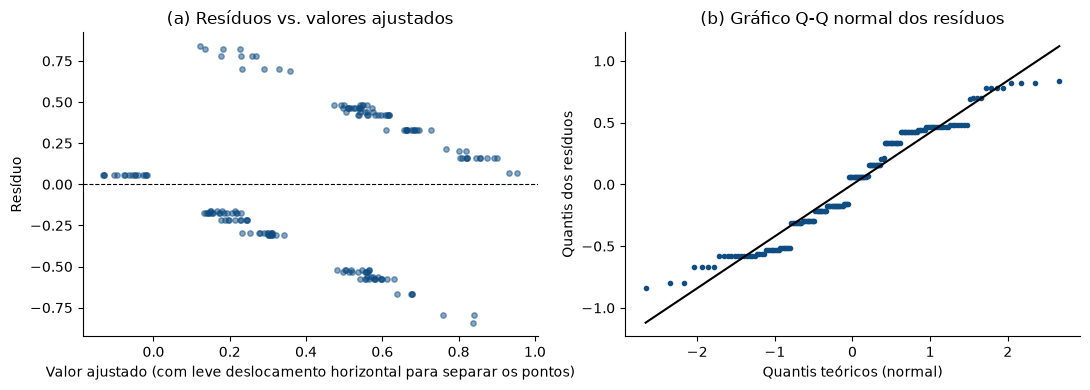

In [22]:
plot_residual_diagnostics(p7_final, FIG_DIR / "f3_fig09_p7_residuos.png")

**(c) Resultado.**

- **Proporção que pretende estagiar até o 3º ano (n = 179):** 75% no 1º ano, 53% no 2º ano e 14% no 3º ano ou mais.
- **Eliminação para trás:** saíram, nesta ordem, Objetivo atual (p = 0,283), Tempo no grupo (p = 0,179), Categoria do grupo (p = 0,089) e Horas semanais (p = 0,051). Ficaram **Grande área do curso** (F parcial = 3,42; gl = 4; 172; p = 0,010) e **Ano na Poli**.
- **Categoria do grupo:** não se mantém depois de controlar o ano e o curso (p = 0,089), o que é coerente com a P3, em que a categoria não se associou ao estágio antecipado (p = 0,15).
- **Horas semanais:** ficaram no limite (p = 0,051; saíram por muito pouco). O critério era p ≥ 0,05 e foi seguido, sem forçar uma interpretação para esse valor.
- **F parcial conjunto (completo vs. final):** F(9; 163) = 1,98, p = 0,045. Rejeita-se $H_0$ por pouco, ou seja, os 4 blocos retirados, em conjunto, acrescentam algo ao modelo final, embora cada um não tenha sido significativo em cada passo da eliminação (testes sequenciais, condicionais aos blocos que ainda estavam no modelo). O R² ajustado cai de 0,275 (completo) para 0,238 (final). Isso é uma ressalva ao modelo reduzido.
- **Ajuste do modelo final:** R² = 0,264 (R² ajustado = 0,238); F global = 10,28, p < 0,001.
- **Coeficientes** (em pontos percentuais de probabilidade, dados os demais):
    - 2º ano vs. 1º ano: −26 pontos (IC 95%: −46 a −7; p = 0,007);
    - 3º ano ou mais vs. 1º ano: −62 pontos (IC 95%: −82 a −43; p < 0,001);
    - Mecânica, Mecatrônica & Naval vs. Civil & Ambiental: −23 pontos (IC 95%: −43 a −4; p = 0,018);
    - Elétrica & Computação (+4; p = 0,63), Produção (+14; p = 0,21) e Outras Engenharias (−2; p = 0,90) não se distinguem significativamente de Civil & Ambiental.
- **Efeito do ano:** a queda com o ano é a maior do modelo e reflete sobretudo a restrição mecânica descrita em (b), que atinge de forma mais direta quem está no 4º ano ou depois. Por isso, o ano é lido como controle, não como achado.
- **Cenários a priori (15 perfis):** os valores estimados vão de −6% (3º ano ou mais, Mecânica, Mecatrônica & Naval) a 93% (1º ano, Produção). **Uma estimativa sai de [0, 100%]**: a de 3º ano ou mais em Mecânica, Mecatrônica & Naval (−6%). Os IC 95% da média também saem do intervalo em 6 perfis: o limite superior passa de 100% em 4 perfis do 1º ano (Civil & Ambiental, Elétrica & Computação, Produção e Outras Engenharias), e o limite inferior fica abaixo de 0% em 3º ano ou mais, Mecânica, Mecatrônica & Naval e 3º ano ou mais, Outras Engenharias. Os IP 95% individuais saem do intervalo em todos os 15 perfis, o que mostra que o modelo compara perfis, mas não prevê pessoas.
- **Resíduos:** formam duas faixas de pontos, uma acima e outra abaixo de zero, porque $Y$ só vale 0 ou 1; o Q-Q mostra degraus e as caudas se afastam da reta. É o que se esperava das limitações declaradas em (b). Os valores ajustados vão de −0,06 a 0,93 (os mesmos 15 valores dos perfis), e a faixa de pontos perto de zero, à esquerda, corresponde ao perfil com previsão negativa.

**(d)** Figuras `f3_fig08` e `f3_fig09`, tabelas `f3_tab20` a `f3_tab22`.

**(e) Conclusão para o relatório.** Dado o ano na Poli, a grande área do curso é o único bloco, além do ano, mantido pelo critério de eliminação (p = 0,010): alunos de Mecânica, Mecatrônica & Naval têm, em média, 23 pontos percentuais a menos que os de Civil & Ambiental. A exclusão da categoria do grupo (p = 0,089) e das horas (p = 0,051) é limítrofe, pois o F conjunto dos blocos retirados rejeita por pouco (p = 0,045). A queda com o ano (−62 pontos no 3º ano ou mais) é sobretudo mecânica, e o ano entra como controle. O modelo explica 26% da variação (R² = 0,264), com uma previsão fora de 0–100%: os resultados são associações aproximadas.

## 9. Síntese da frente e limitações

**Síntese.**

1. **P1 — Área pretendida, grupo e curso:** a área pretendida está fortemente associada à categoria do grupo (χ²(8) = 95,0; p < 0,001; V = 0,50) e à grande área do curso (χ²(12) = 60,4; p < 0,001; V = 0,35). Nos grupos de Mercado Financeiro, 65% miram Mercado Financeiro; nos de Engenharia, 60% miram Indústria/Engenharia.
2. **P2 — Motivação:** associação moderada e com p perto do limite (χ²(12) = 22,2; p = 0,035; V = 0,20), concentrada em Mercado Financeiro: 43% de quem entrou por aprendizado técnico miram essa área, contra 13% de quem entrou por experiência prática ou por desenvolvimento pessoal.
3. **P3 — Estágio por categoria:** sem evidência de associação (χ²(2) = 3,79; p = 0,15). Pretendem estagiar até o 3º ano 50% em Consultoria & Negócios, 38% em Mercado Financeiro e 34% em Engenharia.
4. **P4 — Objetivo por ano:** associação moderada a forte (χ²(6) = 28,0; p < 0,001; V = 0,28). "Estágio" é o objetivo de 46% no 3º ano ou mais, contra 18% no 1º e 16% no 2º ano (comparação entre turmas).
5. **P6 — Média por área pretendida:** a importância da média varia com a área (F(5; 181) = 2,74; p = 0,021; η² = 0,07), mas no sentido oposto ao da hipótese: Mercado Financeiro (2,59) e Consultoria (2,73) ficam abaixo de Indústria/Engenharia (3,29), e o contraste a priori (−0,45; p = 0,14) não é significativo. A média ponderada não difere entre as áreas (p = 0,89).
6. **P7 — Modelo explicativo:** dado o ano, só a grande área do curso fica no modelo pelo critério de eliminação (p = 0,010; Mecânica, Mecatrônica & Naval −23 pontos em relação a Civil & Ambiental). Categoria do grupo (p = 0,089) e horas (p = 0,051) saem no limite, e o F conjunto (F(9; 163) = 1,98; p = 0,045) mostra que a exclusão é limítrofe. R² = 0,264.

**Limitações.**

- **Sem grupo de controle:** todos os alunos fazem extensão. Os resultados são associações, não efeitos causais, e há possível autosseleção (o aluno pode escolher o grupo pela área que já mira).
- **Grupo e curso se sobrepõem:** a categoria do grupo e a grande área do curso são fortemente associadas (Frente 1: χ²(8) = 69,3; V = 0,43). Por isso, os dois testes da P1 não separam o efeito do grupo do efeito do curso.
- **Momento do estágio = intenção:** a maioria ainda não chegou ao 3º ano (só 9 alunos estão no 4º ou 5º ano). A P3 e a P7 falam de quem *pretende* estagiar mais cedo.
- **Comparação entre turmas, não acompanhamento:** os dados são de um único momento. A P4 e o efeito do ano na P7 comparam turmas diferentes, não as mesmas pessoas ao longo do tempo.
- **Agrupamentos para o qui-quadrado:** os agrupamentos (`f3_tab02`) e as exclusões ("Outros" na P2, "Indefinido" na P1b) foram escolhidos para cumprir o critério de no máximo cerca de 20% de caselas com esperado abaixo de 5. A P1a e a P2 ficam exatamente no limite (20%).
- **Modelo de probabilidade linear:** a variância dos resíduos não é constante, os resíduos não são normais e uma previsão sai de 0–100% (−6%). A regressão logística seria o modelo natural, mas está fora dos métodos da disciplina.
- **Média ponderada aproximada pelo ponto médio das faixas:** por isso a P6 foi checada também na versão ordinal (3 faixas).
- **n pequeno em algumas categorias:** Mercado Financeiro tem 34 alunos como categoria de grupo e Indefinido tem 20 como área pretendida, então as estimativas dessas categorias são imprecisas.